## Lab # 11: Hierarchical Agglomerative Clustering

### **Student Information**
- **Name**: Abdul Hayy Khan
- **Roll No**: 24F-AI-051

### Lab Tasks:

Task 1: Load and Explore Data

In [1]:
# import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [2]:
# load Iris dataset
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

# display first five rows
print("First five rows:")
print(X.head())

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
# dataset information
print("\nDataset shape:", X.shape)
print("\nFeature names:")
print(X.columns.tolist())

print("\nTarget classes:")
print(iris.target_names)


Dataset shape: (150, 4)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa' 'versicolor' 'virginica']


In [4]:
# check missing values
print("\nMissing values:")
print(X.isnull().sum())


Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


Task 2: Data Preprocessing

In [5]:
# import standard scaler
from sklearn.preprocessing import StandardScaler

In [6]:
# standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [7]:
# display standardized data
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=iris.feature_names
)

print("Standardized data:")
print(X_scaled_df.head())

Standardized data:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0          -0.900681          1.019004          -1.340227         -1.315444
1          -1.143017         -0.131979          -1.340227         -1.315444
2          -1.385353          0.328414          -1.397064         -1.315444
3          -1.506521          0.098217          -1.283389         -1.315444
4          -1.021849          1.249201          -1.340227         -1.315444


Task 3: Create Dendrogram


In [8]:
# import hierarchical clustering functions
from scipy.cluster.hierarchy import dendrogram, linkage

In [9]:
# perform hierarchical linkage
linked = linkage(X_scaled, method='ward')

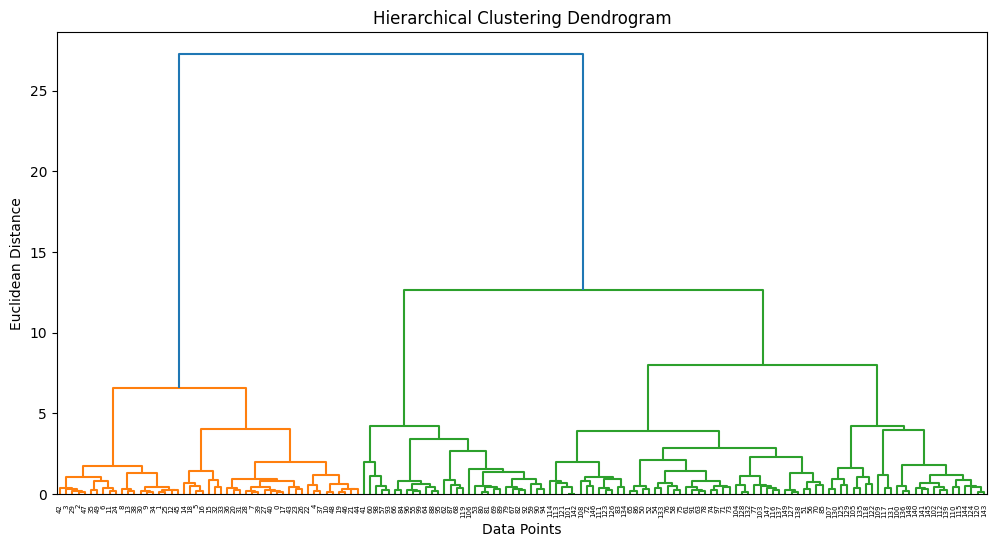

In [10]:
# plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

Task 4: Apply Agglomerative Clustering


In [11]:
# import agglomerative clustering
from sklearn.cluster import AgglomerativeClustering

In [12]:
# create the clustering model
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

In [13]:
# fit model and predict clusters
clusters = hc.fit_predict(X_scaled)

In [14]:
# add cluster labels to dataset
X['Cluster'] = clusters

In [15]:
# display results
print("Cluster assignments:")
print(X.head(10))

Cluster assignments:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   Cluster  
0        1  
1        1  
2        1  
3        1  
4        1  
5        1  
6        1  
7    

In [16]:
# count samples in each cluster
print("\nCluster counts:")
print(pd.Series(clusters).value_counts().sort_index())


Cluster counts:
0    71
1    49
2    30
Name: count, dtype: int64


Task 5: Visualize Clusters


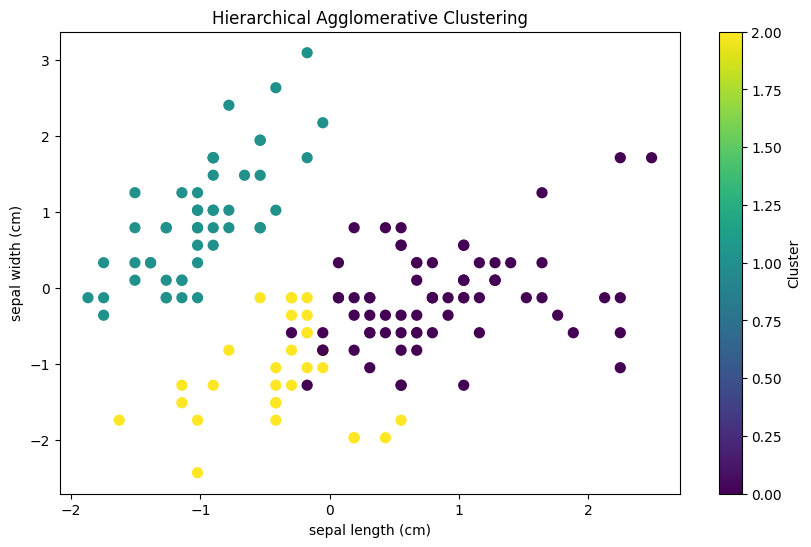

In [17]:
# plot clusters using first two features
plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis',
    s=50
)

plt.title("Hierarchical Agglomerative Clustering")
plt.xlabel(iris.feature_names[0])
plt.ylabel(iris.feature_names[1])

plt.colorbar(label="Cluster")
plt.show()

Task 6: Evaluation

In [18]:
# import adjusted rand index
from sklearn.metrics import adjusted_rand_score

In [19]:
# calculate ARI
ari = adjusted_rand_score(y, clusters)

In [20]:
# display evaluation result
print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.6153
